CELL 1 — IMPORT LIBRARY

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import load_workbook, Workbook
from openpyxl.styles import Font, Alignment
from google.colab import files
from datetime import datetime
import json, warnings
warnings.filterwarnings('ignore')

print("✅ Library siap.")

✅ Library siap.


CELL 2 — KONFIGURASI SKENARIO

In [2]:
SKENARIO = {
    "Skenario1": {
        "referensi": {"R1": {"jarak_m": 0.5}, "R2": {"jarak_m": 2.0}},
        "urutan_ref": ["R1", "R2"],
    },
    "Skenario2": {
        "referensi": {"R1": {"jarak_m": 0.5}, "R2": {"jarak_m": 1.25}, "R3": {"jarak_m": 2.0}},
        "urutan_ref": ["R1", "R2", "R3"],
    },
}

print("✅ Konfigurasi siap.")


✅ Konfigurasi siap.


CELL 3 — FUNGSI PREPROCESSING



In [3]:
"""Gaussian Filter — Persamaan 3.1, 3.2, 2.3, 3.3, 3.4."""
def gaussian_filter(rssi_array: np.ndarray, k: float = 1.0, q_threshold: float = 0.5) -> dict:
    n, k_used = len(rssi_array), k
    while True:
        xe = np.mean(rssi_array)
        omega = np.sqrt(np.mean((rssi_array - xe) ** 2))
        mask = np.abs(rssi_array - xe) < k_used * omega
        data_bersih = rssi_array[mask]
        P = (len(data_bersih) / n) * 100
        if P >= q_threshold * 100 or k_used >= 3:
            break
        k_used += 1
    xe_bersih = np.mean(data_bersih) if len(data_bersih) > 0 else xe
    return {'xe_bersih': xe_bersih, 'data_bersih': data_bersih}

"""Kalman Filter — Persamaan 2.4 s.d. 2.9."""
def kalman_filter(rssi_array: np.ndarray, phi=1.0, Q=0.01, Rv=0.1, P0=1.0) -> float:
    x_est, P_est = rssi_array[0], P0
    for zk in rssi_array:
        x_pred = phi * x_est
        P_pred = phi * P_est * phi + Q
        Kk = P_pred / (P_pred + Rv)
        x_est = x_pred + Kk * (zk - x_pred)
        P_est = (1 - Kk) * P_pred
    return x_est

"""Pipeline Gaussian → Kalman, return xk_final."""
def preprocessing(rssi_array: np.ndarray) -> float:
    return kalman_filter(gaussian_filter(rssi_array)['data_bersih'])

"""Baca satu sheet, return (rssi_array, jarak_cm)."""
def baca_sheet_rssi(ws) -> tuple:
    rows = list(ws.iter_rows(values_only=True))
    if len(rows) < 2:
        return None, None
    df = pd.DataFrame(rows[1:], columns=rows[0])
    df['RSSI (dBm)'] = pd.to_numeric(df['RSSI (dBm)'], errors='coerce')
    df = df.dropna(subset=['RSSI (dBm)'])
    jarak = float(df['Jarak Aktual (cm)'].iloc[0]) if 'Jarak Aktual (cm)' in df.columns else None
    return df['RSSI (dBm)'].values, jarak

"""Pembulatan konvensional ke cm terdekat."""
def bulat_cm(nilai_m: float) -> int:
    return int(np.floor(nilai_m * 100 + 0.5))

"""Hitung MAE dan RMSE dari hasil yang sudah dibulatkan."""
def hitung_metrik(detail: list) -> tuple:
    y_act = np.array([h['jarak_aktual_cm'] for h in detail], dtype=float)
    y_pred = np.array([h['jarak_prediksi_cm'] for h in detail], dtype=float)
    mae = float(np.mean(np.abs(y_pred - y_act)))
    rmse = float(np.sqrt(np.mean((y_pred - y_act) ** 2)))
    return mae, rmse

print("✅ Fungsi preprocessing siap.")

✅ Fungsi preprocessing siap.


CELL 4 — FUNGSI SVR MANUAL

In [4]:
"""Kernel RBF untuk vektor — Persamaan 2.15."""
def kernel_rbf_vec(xi: np.ndarray, xj: np.ndarray, gamma: float) -> float:
    diff = xi - xj
    return float(np.exp(-gamma * np.dot(diff, diff)))

"""Prediksi jarak — Persamaan 2.16."""
def prediksi_svr_vec(x_test: np.ndarray, X_train: np.ndarray, alpha_diff: np.ndarray, b: float, gamma: float) -> float:
    kvals = np.array([kernel_rbf_vec(X_train[i], x_test, gamma) for i in range(len(X_train))])
    return float(np.dot(alpha_diff, kvals) + b)

"""Koreksi vektor input NLOS ke skala LOS dengan Weighted Inverse Distance."""
def koreksi_vektor_input(vektor_nlos: np.ndarray, xk_los_per_tag: dict, jarak_ref: dict, urutan_ref: list, jarak_target_m: float) -> np.ndarray:
    vektor_adj = vektor_nlos.copy().astype(float)
    delta_per_ref = {}

    for ref_idx, tag in enumerate(urutan_ref):
        xk_los_ref = xk_los_per_tag[tag]
        xk_nlos_ref = vektor_nlos[ref_idx]
        delta_per_ref[tag] = xk_nlos_ref - xk_los_ref
        vektor_adj[ref_idx] -= delta_per_ref[tag]

    bobot = {}
    for tag in urutan_ref:
        d_ref = jarak_ref.get(tag, 1.0)
        dist = abs(jarak_target_m - d_ref)
        bobot[tag] = 1.0 / (dist + 0.01)

    total_bobot = sum(bobot.values())
    for tag in bobot:
        bobot[tag] /= total_bobot

    delta_target = sum(bobot[tag] * delta_per_ref[tag] for tag in urutan_ref)
    vektor_adj[-1] -= delta_target
    return vektor_adj

print("✅ Fungsi SVR manual dan koreksi weighted siap.")

✅ Fungsi SVR manual dan koreksi weighted siap.


CELL 5 — UPLOAD SEMUA FILE

In [15]:
""" Upload :
    1. model_svr_landmarc_*.json         → model SVR adaptif
    2. data_*_LOS_Referensi_*.xlsx       → referensi LOS
    3. data_*_LOS_Target_*cm_*.xlsx      → target LOS
       Skenario 1: sheet Target + R1 + R2
       Skenario 2: sheet Target + R1 + R2 + R3
    4. data_*_NLOS_*_Referensi_*.xlsx    → referensi NLOS
       Skenario 1: sheet Target + R1 + R2
       Skenario 2: sheet Target + R1 + R2 + R3
    5. data_*_NLOS_*_Target_*cm_*.xlsx   → target NLOS
"""
print("Upload semua file:")
print("  1. model_svr_landmarc_*.json")
print("  2. Semua file referensi LOS")
print("  3. Semua file target LOS")
print("  4. Semua file referensi NLOS")
print("  5. Semua file target NLOS")
print()

uploaded = files.upload()
filenames = list(uploaded.keys())

model_files = [f for f in filenames if f.endswith('.json')]
ref_los_files = [f for f in filenames if 'Referensi' in f and 'NLOS' not in f and f.endswith('.xlsx')]
target_los_files = [f for f in filenames if 'Target' in f and 'NLOS' not in f and f.endswith('.xlsx')]
ref_nlos_files = [f for f in filenames if 'Referensi' in f and 'NLOS' in f and f.endswith('.xlsx')]
target_nlos_files = [f for f in filenames if 'Target' in f and 'NLOS' in f and f.endswith('.xlsx')]

print(f"\n✅ Model JSON      : {len(model_files)} file")
print(f"✅ Ref LOS         : {len(ref_los_files)} file")
print(f"✅ Target LOS      : {len(target_los_files)} file")
print(f"✅ Ref NLOS        : {len(ref_nlos_files)} file")
print(f"✅ Target NLOS     : {len(target_nlos_files)} file")

Upload semua file:
  1. model_svr_landmarc_*.json
  2. Semua file referensi LOS
  3. Semua file target LOS
  4. Semua file referensi NLOS
  5. Semua file target NLOS



Saving data_Skenario2_LOS_Referensi_20260511_123032.xlsx to data_Skenario2_LOS_Referensi_20260511_123032.xlsx
Saving data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx to data_Skenario2_LOS_Target_80cm_20260511_123901.xlsx
Saving data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx to data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx
Saving data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx to data_Skenario2_LOS_Target_100cm_20260511_124629.xlsx
Saving data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx to data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx
Saving data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx to data_Skenario2_LOS_Target_140cm_20260511_125405.xlsx
Saving data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx to data_Skenario2_LOS_Target_170cm_20260511_130502.xlsx
Saving data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx to data_Skenario2_NLOS_Banyak_Referensi_20260511_011823.xlsx
Saving data_Skenario2_NLOS_Banyak_Target_80cm_20260511_012539.xlsx to da

CELL 6 — LOAD MODEL SVR ADAPTIF

In [16]:
def load_model(json_file: str) -> dict:
    with open(json_file, 'r') as f:
        raw = json.load(f)

    models = {}
    for nama, p in raw.items():
        models[nama] = {
            'gamma': p['gamma'], 'C': p['C'], 'epsilon': p['epsilon'], 'b': p['b'],
            'alpha_diff': np.array(p['alpha_diff']), 'X_train': np.array(p['X_train']),
            'y_train': np.array(p['y_train']), 'urutan_ref': p['urutan_ref'],
            'n_fitur': p['n_fitur'], 'jarak_ref_per_tag': p.get('jarak_ref_m', {}),
        }
    return models

model_svr = {}
for mf in model_files:
    model_svr.update(load_model(mf))

nama_skenario = list(model_svr.keys())[0]
urutan_ref = model_svr[nama_skenario]['urutan_ref']
ref_info = SKENARIO[nama_skenario]['referensi']
jarak_ref = model_svr[nama_skenario]['jarak_ref_per_tag']

print(f"✅ Model SVR-LANDMARC dimuat: {nama_skenario}")
print(f"   Urutan ref : {urutan_ref}")
print(f"   Jarak ref  : {ref_info}")

✅ Model SVR-LANDMARC dimuat: Skenario2
   Urutan ref : ['R1', 'R2', 'R3']
   Jarak ref  : {'R1': {'jarak_m': 0.5}, 'R2': {'jarak_m': 1.25}, 'R3': {'jarak_m': 2.0}}


CELL 7 — BACA DAN PREPROCESSING DATA

In [17]:
"""Deteksi kondisi file; nama file lama dipetakan ke kondisi penelitian."""
def deteksi_kondisi(fname: str) -> str:
    condition_map = {
        'NLOS_Sedikit': 'NLOS_Satu_Halangan',
        'NLOS_Sedang': 'NLOS_Tiga_Halangan',
        'NLOS_Banyak': 'NLOS_Lima_Halangan',
    }
    fname_norm = fname.replace('_', '').lower()
    for nama_file, kondisi_baru in condition_map.items():
        if nama_file.replace('_', '').lower() in fname_norm:
            return kondisi_baru
    return 'LOS'

"""Ambil nama skenario dari nama file."""
def deteksi_skenario(fname: str) -> str:
    parts = fname.replace('.xlsx', '').split('_')
    return next((p for p in parts if 'Skenario' in p), nama_skenario)

"""Baca file target dengan sheet Target + R1 + R2 + ...."""
def baca_target(filelist: list, urutan_ref: list) -> list:
    hasil = []
    for fname in filelist:
        wb = load_workbook(fname)
        kondisi = deteksi_kondisi(fname)
        skenario = deteksi_skenario(fname)
        data_sheets = {}

        for sname in wb.sheetnames:
            if sname.lower() == 'ringkasan':
                continue
            rssi_arr, jarak = baca_sheet_rssi(wb[sname])
            if rssi_arr is not None and len(rssi_arr) > 0:
                data_sheets[sname] = {'xk': preprocessing(rssi_arr), 'jarak_cm': jarak}

        if 'Target' not in data_sheets:
            continue

        jarak_cm = data_sheets['Target']['jarak_cm'] or 0.0
        xk_target = data_sheets['Target']['xk']
        xk_refs = {ref: data_sheets[ref]['xk'] if ref in data_sheets else 0.0 for ref in urutan_ref}
        vektor = [xk_refs[r] for r in urutan_ref] + [xk_target]
        hasil.append({
            'jarak_aktual_m': jarak_cm / 100.0, 'jarak_aktual_cm': jarak_cm,
            'xk_target': xk_target, 'xk_refs': xk_refs, 'vektor_input': np.array(vektor),
            'kondisi': kondisi, 'skenario': skenario,
        })

    hasil.sort(key=lambda x: (x['kondisi'], x['jarak_aktual_m']))
    return hasil

"""Baca file referensi → {skenario: {kondisi: {tag: xk}}}."""
def baca_referensi(filelist: list) -> dict:
    hasil = {}
    for fname in filelist:
        wb = load_workbook(fname)
        skenario = deteksi_skenario(fname)
        kondisi = deteksi_kondisi(fname)
        hasil.setdefault(skenario, {}).setdefault(kondisi, {})

        for sname in wb.sheetnames:
            if sname.lower() == 'ringkasan':
                continue
            rssi_arr, _ = baca_sheet_rssi(wb[sname])
            if rssi_arr is not None and len(rssi_arr) > 0:
                hasil[skenario][kondisi][sname] = preprocessing(rssi_arr)
    return hasil

print("=" * 60)
print("  MEMBACA DAN PREPROCESSING SEMUA DATA")
print("=" * 60)

data_target_los = baca_target(target_los_files, urutan_ref)
data_target_nlos = baca_target(target_nlos_files, urutan_ref)
data_referensi = baca_referensi(ref_los_files + ref_nlos_files)

print(f"\n✅ Target LOS  : {len(data_target_los)} file")
print(f"✅ Target NLOS : {len(data_target_nlos)} file")

jarak_training = model_svr[nama_skenario]['y_train'] * 100
jarak_training_cm = [round(j) for j in jarak_training]
data_train_los = [d for d in data_target_los if round(d['jarak_aktual_cm']) in jarak_training_cm]
data_uji_los = [d for d in data_target_los if round(d['jarak_aktual_cm']) not in jarak_training_cm]

print(f"\n  Data training LOS : {[int(d['jarak_aktual_cm']) for d in data_train_los]} cm")
print(f"  Data pengujian LOS: {[int(d['jarak_aktual_cm']) for d in data_uji_los]} cm")
print("  Data NLOS         : seluruh titik digunakan sebagai data pengujian.")

  MEMBACA DAN PREPROCESSING SEMUA DATA

✅ Target LOS  : 6 file
✅ Target NLOS : 18 file

  Data training LOS : [80, 100, 140, 170] cm
  Data pengujian LOS: [90, 110] cm
  Data NLOS         : seluruh titik digunakan sebagai data pengujian.


CELL 8 — MODEL 1: LANDMARC

In [19]:
"""
Algoritma LANDMARC — Persamaan 2.10 s/d 2.13:
  1. Ej = |RSSI_target - RSSI_referensi|    (Pers. 2.10)
  2. wi = (1/Ei²) / Σ(1/Ej²)                (Pers. 2.13)
  3. d_final = Σ(wi × di)                   (Pers. 2.12)
"""

"""Algoritma LANDMARC — Persamaan 2.10 s.d. 2.13."""
def landmarc_predict(xk_target: float, xk_refs: dict, ref_info: dict) -> float:
    distances = []
    for tag, xk_ref in xk_refs.items():
        Ej = abs(xk_target - xk_ref)
        distances.append({'tag': tag, 'Ej': 1e-10 if Ej == 0 else Ej, 'jarak_m': ref_info[tag]['jarak_m']})

    sum_inv_sq = sum(1.0 / (d['Ej'] ** 2) for d in distances)
    for d in distances:
        d['wi'] = (1.0 / (d['Ej'] ** 2)) / sum_inv_sq

    return sum(d['wi'] * d['jarak_m'] for d in distances)

"""Uji LANDMARC pada semua data target."""
def uji_landmarc(data_list: list, xk_refs_kondisi: dict, ref_info: dict) -> dict:
    hasil = []
    for d in data_list:
        pred_m = landmarc_predict(d['xk_target'], xk_refs_kondisi, ref_info)
        aktual_cm = bulat_cm(d['jarak_aktual_m'])
        pred_cm = bulat_cm(pred_m)
        hasil.append({'jarak_aktual_cm': aktual_cm, 'jarak_prediksi_cm': pred_cm, 'error_cm': abs(pred_cm - aktual_cm)})

    mae, rmse = hitung_metrik(hasil)
    return {'detail': hasil, 'mae_cm': mae, 'rmse_cm': rmse}

print("✅ Fungsi LANDMARC siap.")

✅ Fungsi LANDMARC siap.


CELL 9 — MODEL 2: SVR-LANDMARC

In [20]:
"""
  SVR-LANDMARC = model LOS digunakan langsung
  untuk kondisi NLOS tanpa koreksi apapun.
"""

"""SVR-LANDMARC menggunakan vektor input langsung tanpa koreksi."""
"""Uji SVR-LANDMARC pada semua data target."""
def uji_svr_landmarc(data_list: list, model: dict) -> dict:
    hasil = []
    for d in data_list:
        pred_m = prediksi_svr_vec(d['vektor_input'], model['X_train'], model['alpha_diff'], model['b'], model['gamma'])
        aktual_cm = bulat_cm(d['jarak_aktual_m'])
        pred_cm = bulat_cm(pred_m)
        hasil.append({'jarak_aktual_cm': aktual_cm, 'jarak_prediksi_cm': pred_cm, 'error_cm': abs(pred_cm - aktual_cm)})

    mae, rmse = hitung_metrik(hasil)
    return {'detail': hasil, 'mae_cm': mae, 'rmse_cm': rmse}

print("✅ Fungsi SVR-LANDMARC siap.")

✅ Fungsi SVR-LANDMARC siap.


CELL 10 — MODEL 3: SVR-LANDMARC ADAPTIF

In [21]:
"""
  SVR-LANDMARC Adaptif = model LOS + koreksi vektor input
  menggunakan Weighted Inverse Distance saat kondisi NLOS.
"""
"""
  - LOS: prediksi langsung.
  - NLOS: koreksi vektor dengan weighted inverse distance.
"""
def uji_svr_adaptif(data_list: list, model: dict, xk_refs_kondisi: dict, kondisi: str) -> dict:
    xk_los_per_tag = {tag: float(np.mean(model['X_train'][:, ref_idx])) for ref_idx, tag in enumerate(model['urutan_ref'])}

    hasil = []
    for d in data_list:
        if kondisi == 'LOS':
            x_input = d['vektor_input']
        else:
            x_input = koreksi_vektor_input(d['vektor_input'], xk_los_per_tag, model['jarak_ref_per_tag'], model['urutan_ref'], d['jarak_aktual_m'])

        pred_m = prediksi_svr_vec(x_input, model['X_train'], model['alpha_diff'], model['b'], model['gamma'])
        aktual_cm = bulat_cm(d['jarak_aktual_m'])
        pred_cm = bulat_cm(pred_m)
        hasil.append({'jarak_aktual_cm': aktual_cm, 'jarak_prediksi_cm': pred_cm, 'error_cm': abs(pred_cm - aktual_cm)})

    mae, rmse = hitung_metrik(hasil)
    return {'detail': hasil, 'mae_cm': mae, 'rmse_cm': rmse}

print("✅ Fungsi SVR-LANDMARC Adaptif siap.")

✅ Fungsi SVR-LANDMARC Adaptif siap.


CELL 11 — PENGUJIAN MODEL PEMBANDING

In [22]:
print("=" * 60)
print("  PENGUJIAN KETIGA MODEL")
print("=" * 60)

semua_kondisi = ['LOS'] + [k for k in sorted({d['kondisi'] for d in data_target_nlos}) if k != 'LOS']
hasil_semua = {}
model = model_svr[nama_skenario]

NAMA_MODEL = {
    'SVR_LANDMARC_Adaptif': 'SVR-LANDMARC Adaptif',
    'LANDMARC': 'LANDMARC',
    'SVR_LANDMARC': 'SVR-LANDMARC',
}

for kondisi in semua_kondisi:
    if kondisi == 'LOS':
        daftar_uji = [('Training', data_train_los), ('Pengujian', data_uji_los)]
    else:
        data_nlos = [d for d in data_target_nlos if d['kondisi'] == kondisi and d['skenario'] == nama_skenario]
        daftar_uji = [('Pengujian', data_nlos)]

    xk_refs = data_referensi.get(nama_skenario, {}).get(kondisi, {})
    if not xk_refs:
        xk_refs = data_referensi.get(nama_skenario, {}).get('LOS', {})

    hasil_semua[kondisi] = {}

    for tipe_data, data_list in daftar_uji:
        if not data_list:
            continue

        print(f"\n{'=' * 72}")
        print(f"  {kondisi} — Data {tipe_data}")
        print(f"{'=' * 72}")
        print(f"  {'Jarak':>8} {'SVR-LANDMARC Adaptif':>22} {'LANDMARC':>12} {'SVR-LANDMARC':>15} {'Err A':>8} {'Err LM':>8} {'Err SVR':>9}")
        print(f"  {'-' * 8} {'-' * 22} {'-' * 12} {'-' * 15} {'-' * 8} {'-' * 8} {'-' * 9}")

        h_adaptif = uji_svr_adaptif(data_list, model, xk_refs, kondisi)
        h_landmarc = uji_landmarc(data_list, xk_refs, ref_info)
        h_svr_landmarc = uji_svr_landmarc(data_list, model)

        for i, d in enumerate(data_list):
            a = h_adaptif['detail'][i]
            lm = h_landmarc['detail'][i]
            svr = h_svr_landmarc['detail'][i]
            print(f"  {int(d['jarak_aktual_cm']):>6}cm {a['jarak_prediksi_cm']:>17}cm {lm['jarak_prediksi_cm']:>9}cm {svr['jarak_prediksi_cm']:>12}cm {a['error_cm']:>5}cm {lm['error_cm']:>5}cm {svr['error_cm']:>6}cm")

        print(f"\n  MAE  — {NAMA_MODEL['SVR_LANDMARC_Adaptif']}: {h_adaptif['mae_cm']:.2f} cm | {NAMA_MODEL['LANDMARC']}: {h_landmarc['mae_cm']:.2f} cm | {NAMA_MODEL['SVR_LANDMARC']}: {h_svr_landmarc['mae_cm']:.2f} cm")
        print(f"  RMSE — {NAMA_MODEL['SVR_LANDMARC_Adaptif']}: {h_adaptif['rmse_cm']:.2f} cm | {NAMA_MODEL['LANDMARC']}: {h_landmarc['rmse_cm']:.2f} cm | {NAMA_MODEL['SVR_LANDMARC']}: {h_svr_landmarc['rmse_cm']:.2f} cm")

        hasil_semua[kondisi][tipe_data] = {
            'SVR_LANDMARC_Adaptif': h_adaptif,
            'LANDMARC': h_landmarc,
            'SVR_LANDMARC': h_svr_landmarc,
        }

print("\n✅ Pengujian model pembanding selesai.")

  PENGUJIAN KETIGA MODEL

  LOS — Data Training
     Jarak   SVR-LANDMARC Adaptif     LANDMARC    SVR-LANDMARC    Err A   Err LM   Err SVR
  -------- ---------------------- ------------ --------------- -------- -------- ---------
      80cm                80cm        82cm           80cm     0cm     2cm      0cm
     100cm               100cm       125cm          100cm     0cm    25cm      0cm
     140cm               140cm       130cm          140cm     0cm    10cm      0cm
     170cm               170cm       193cm          170cm     0cm    23cm      0cm

  MAE  — SVR-LANDMARC Adaptif: 0.00 cm | LANDMARC: 15.00 cm | SVR-LANDMARC: 0.00 cm
  RMSE — SVR-LANDMARC Adaptif: 0.00 cm | LANDMARC: 17.73 cm | SVR-LANDMARC: 0.00 cm

  LOS — Data Pengujian
     Jarak   SVR-LANDMARC Adaptif     LANDMARC    SVR-LANDMARC    Err A   Err LM   Err SVR
  -------- ---------------------- ------------ --------------- -------- -------- ---------
      90cm                93cm       124cm           93cm     3

CELL 12 — VISUALISASI PERBANDINGAN

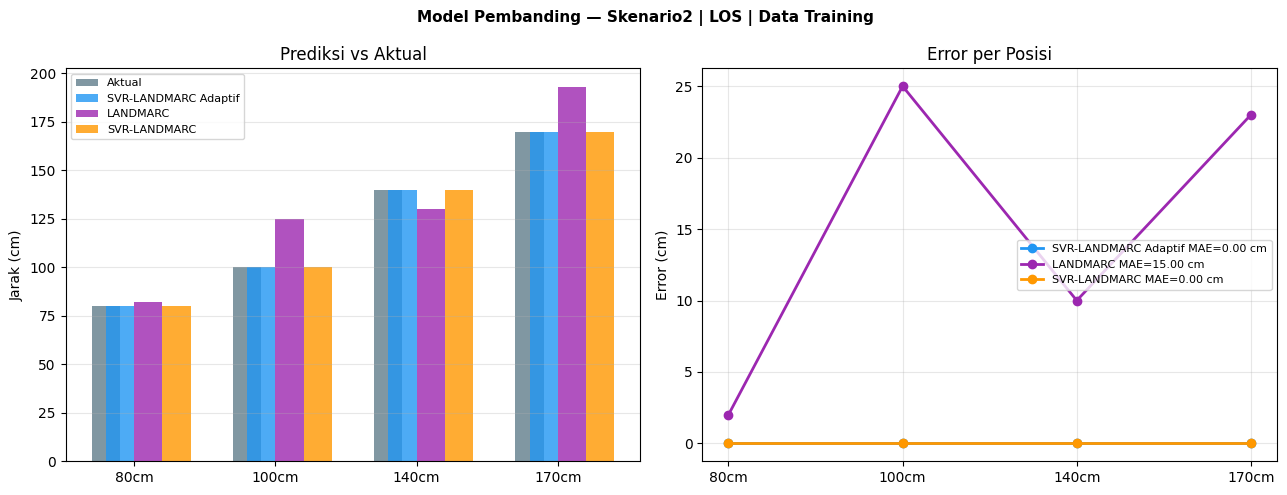

✅ Plot disimpan: pembanding_Skenario2_LOS_Training.png


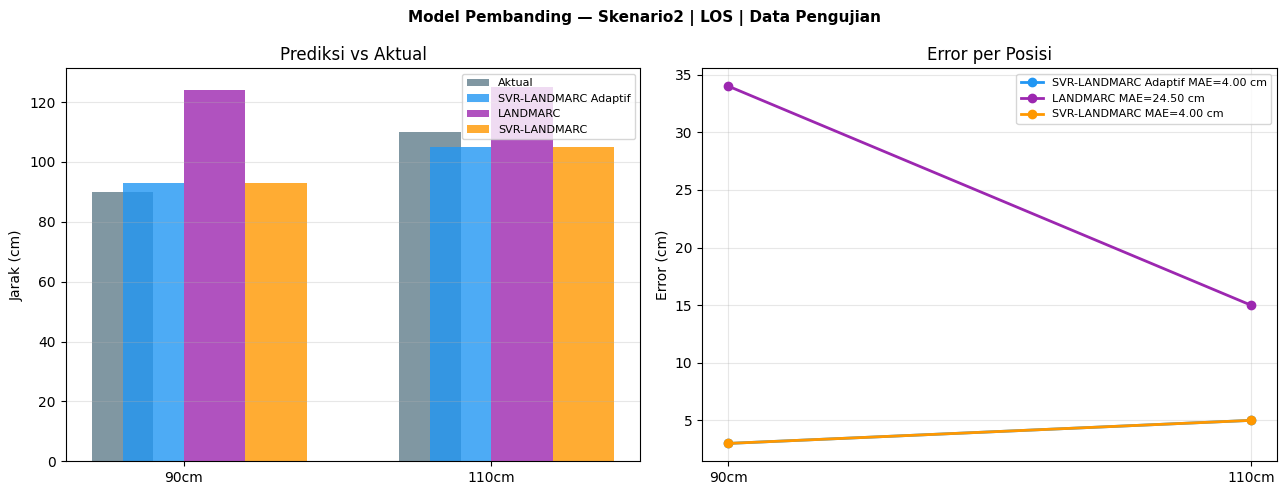

✅ Plot disimpan: pembanding_Skenario2_LOS_Pengujian.png


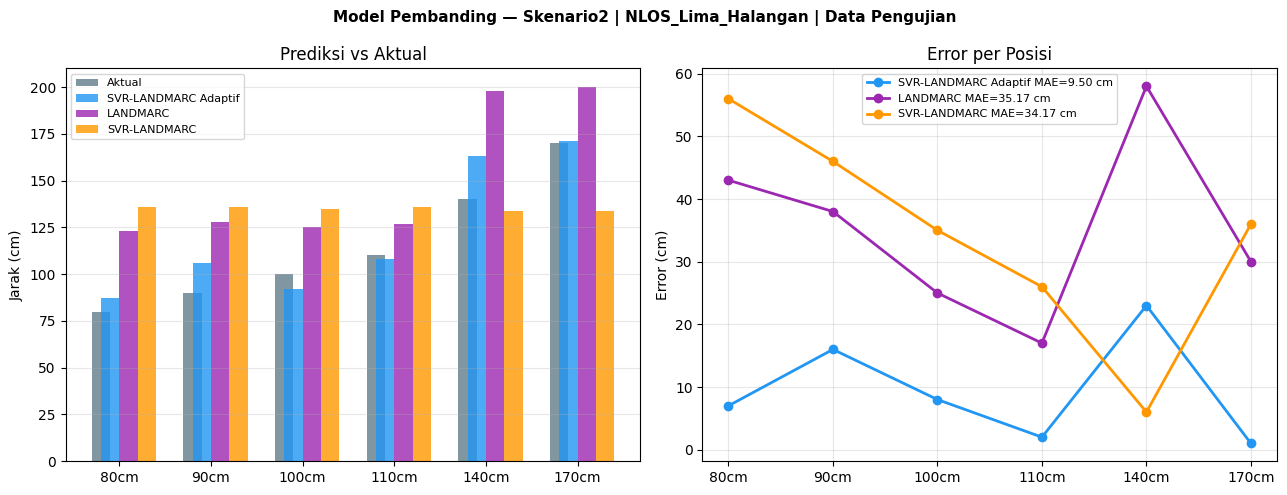

✅ Plot disimpan: pembanding_Skenario2_NLOS_Lima_Halangan_Pengujian.png


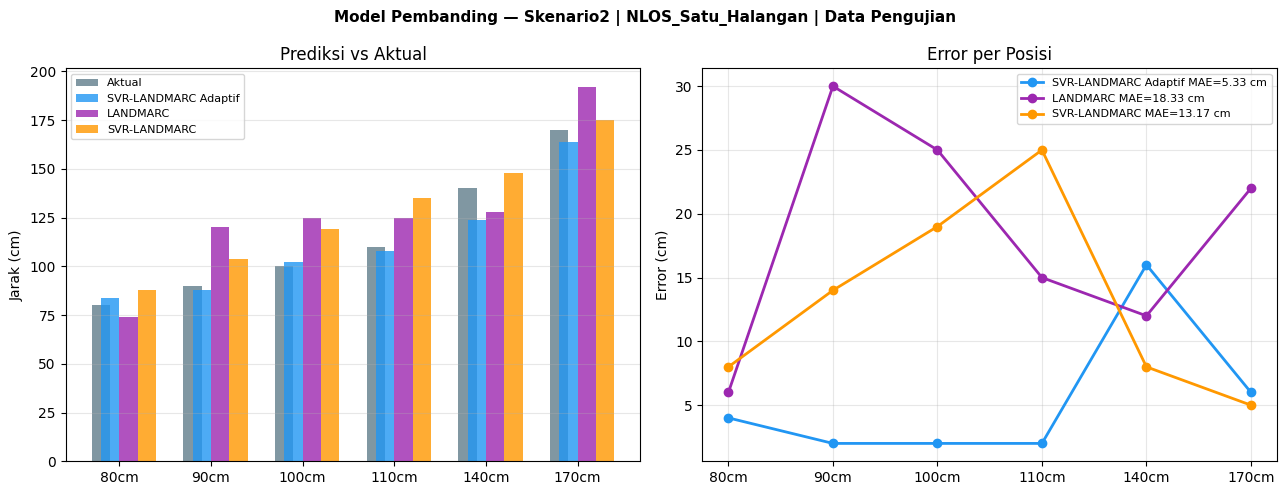

✅ Plot disimpan: pembanding_Skenario2_NLOS_Satu_Halangan_Pengujian.png


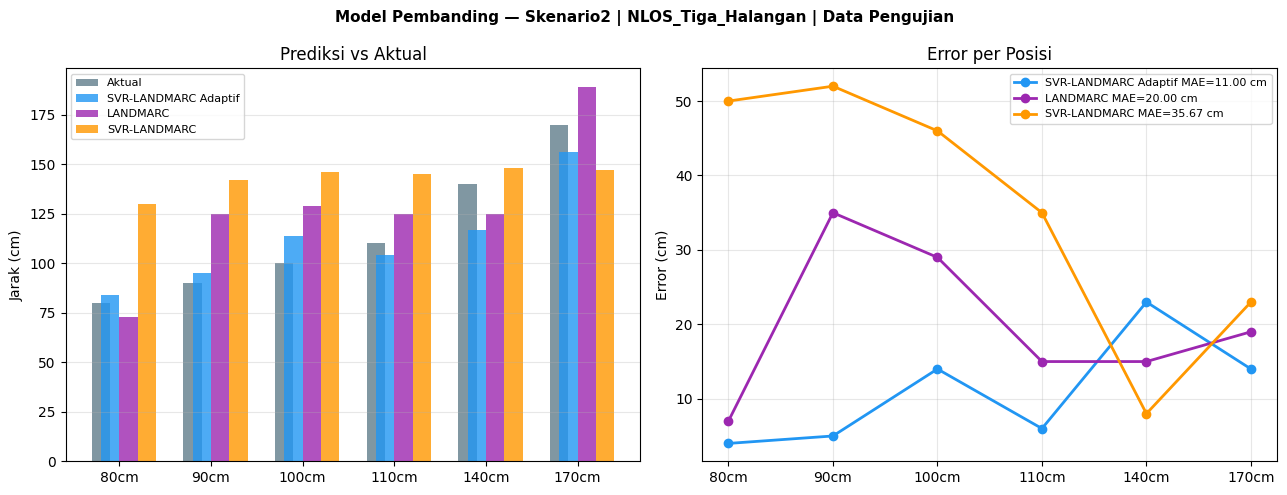

✅ Plot disimpan: pembanding_Skenario2_NLOS_Tiga_Halangan_Pengujian.png


In [23]:
warna = {
    'SVR_LANDMARC_Adaptif': '#2196F3',
    'LANDMARC': '#9C27B0',
    'SVR_LANDMARC': '#FF9800',
}

urutan_model = ['SVR_LANDMARC_Adaptif', 'LANDMARC', 'SVR_LANDMARC']

for kondisi, tipe_dict in hasil_semua.items():
    for tipe_data, model_dict in tipe_dict.items():
        if not model_dict:
            continue

        if kondisi == 'LOS':
            data_list = data_train_los if tipe_data == 'Training' else data_uji_los
        else:
            data_list = [d for d in data_target_nlos if d['kondisi'] == kondisi and d['skenario'] == nama_skenario]

        if not data_list:
            continue

        y_act = np.array([d['jarak_aktual_cm'] for d in data_list])
        x_labels = [f"{int(d['jarak_aktual_cm'])}cm" for d in data_list]
        x_pos, width = np.arange(len(data_list)), 0.2

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        fig.suptitle(f'Model Pembanding — {nama_skenario} | {kondisi} | Data {tipe_data}', fontsize=11, fontweight='bold')

        ax1 = axes[0]
        ax1.bar(x_pos - width, y_act, width, label='Aktual', color='#607D8B', alpha=0.8)
        for i, model_name in enumerate(urutan_model):
            hasil = model_dict[model_name]
            y_pred = np.array([r['jarak_prediksi_cm'] for r in hasil['detail']])
            ax1.bar(x_pos + (i - 0.5) * width, y_pred, width, label=NAMA_MODEL[model_name], color=warna[model_name], alpha=0.8)
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels(x_labels)
        ax1.set_ylabel('Jarak (cm)')
        ax1.set_title('Prediksi vs Aktual')
        ax1.legend(fontsize=8)
        ax1.grid(True, alpha=0.3, axis='y')

        ax2 = axes[1]
        for model_name in urutan_model:
            hasil = model_dict[model_name]
            errors = np.array([r['error_cm'] for r in hasil['detail']])
            ax2.plot(x_labels, errors, 'o-', color=warna[model_name], lw=2, label=f"{NAMA_MODEL[model_name]} MAE={hasil['mae_cm']:.2f} cm")
        ax2.set_ylabel('Error (cm)')
        ax2.set_title('Error per Posisi')
        ax2.legend(fontsize=8)
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        fname_plot = f'pembanding_{nama_skenario}_{kondisi}_{tipe_data}.png'
        plt.savefig(fname_plot, dpi=120, bbox_inches='tight')
        plt.show()
        print(f"✅ Plot disimpan: {fname_plot}")

CELL 13 — RINGKASAN MAE DAN RMSE

In [24]:
print("\n" + "=" * 85)
print("  RINGKASAN MAE DAN RMSE — KETIGA MODEL")
print("=" * 85)
print(f"  {'Kondisi':<22} {'Data':<12} {'SVR-LANDMARC Adaptif':>22} {'LANDMARC':>16} {'SVR-LANDMARC':>17}")
print(f"  {'':22} {'':12} {'MAE|RMSE':>22} {'MAE|RMSE':>16} {'MAE|RMSE':>17}")
print(f"  {'-' * 22} {'-' * 12} {'-' * 22} {'-' * 16} {'-' * 17}")

for kondisi, tipe_dict in hasil_semua.items():
    for tipe_data, model_dict in tipe_dict.items():
        if not model_dict:
            continue
        a = model_dict['SVR_LANDMARC_Adaptif']
        lm = model_dict['LANDMARC']
        svr = model_dict['SVR_LANDMARC']
        print(f"  {kondisi:<22} {tipe_data:<12} {a['mae_cm']:>6.2f}|{a['rmse_cm']:<7.2f} {lm['mae_cm']:>7.2f}|{lm['rmse_cm']:<7.2f} {svr['mae_cm']:>7.2f}|{svr['rmse_cm']:<7.2f}")

print("\n✅ Ringkasan selesai.")


  RINGKASAN MAE DAN RMSE — KETIGA MODEL
  Kondisi                Data           SVR-LANDMARC Adaptif         LANDMARC      SVR-LANDMARC
                                                    MAE|RMSE         MAE|RMSE          MAE|RMSE
  ---------------------- ------------ ---------------------- ---------------- -----------------
  LOS                    Training       0.00|0.00      15.00|17.73      0.00|0.00   
  LOS                    Pengujian      4.00|4.12      24.50|26.28      4.00|4.12   
  NLOS_Lima_Halangan     Pengujian      9.50|12.27     35.17|37.57     34.17|37.61  
  NLOS_Satu_Halangan     Pengujian      5.33|7.30      18.33|20.06     13.17|14.92  
  NLOS_Tiga_Halangan     Pengujian     11.00|12.90     20.00|22.08     35.67|39.03  

✅ Ringkasan selesai.


CELL 14 — SIMPAN HASIL KE EXCEL DAN DOWNLOAD

In [25]:
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"hasil_model_pembanding_{ts}.xlsx"

wb = Workbook()
wb.remove(wb.active)

# SHEET RINGKASAN
ws_sum = wb.create_sheet(title="Ringkasan", index=0)
ws_sum.append(["Skenario", "Kondisi", "Tipe Data", "Model", "MAE (cm)", "RMSE (cm)"])

# SHEET DETAIL
for kondisi, tipe_dict in hasil_semua.items():
    for tipe_data, model_dict in tipe_dict.items():
        if not model_dict:
            continue

        sheet_name = f"{kondisi}_{tipe_data}"[:31]
        ws = wb.create_sheet(title=sheet_name)
        ws.append([
            "No", "Jarak Aktual (cm)",
            "Pred SVR-LANDMARC Adaptif (cm)", "Err SVR-LANDMARC Adaptif (cm)",
            "Pred LANDMARC (cm)", "Err LANDMARC (cm)",
            "Pred SVR-LANDMARC (cm)", "Err SVR-LANDMARC (cm)"
        ])

        h_adaptif = model_dict['SVR_LANDMARC_Adaptif']
        h_landmarc = model_dict['LANDMARC']
        h_svr_landmarc = model_dict['SVR_LANDMARC']
        detail_adaptif = h_adaptif['detail']
        detail_landmarc = h_landmarc['detail']
        detail_svr_landmarc = h_svr_landmarc['detail']

        for i in range(len(detail_adaptif)):
            a, lm, svr = detail_adaptif[i], detail_landmarc[i], detail_svr_landmarc[i]
            ws.append([
                i + 1, int(a['jarak_aktual_cm']), int(a['jarak_prediksi_cm']), int(a['error_cm']),
                int(lm['jarak_prediksi_cm']), int(lm['error_cm']),
                int(svr['jarak_prediksi_cm']), int(svr['error_cm'])
            ])

        ws.append([])
        ws.append(["", "MAE", round(h_adaptif['mae_cm'], 2), "", round(h_landmarc['mae_cm'], 2), "", round(h_svr_landmarc['mae_cm'], 2)])
        ws.append(["", "RMSE", round(h_adaptif['rmse_cm'], 2), "", round(h_landmarc['rmse_cm'], 2), "", round(h_svr_landmarc['rmse_cm'], 2)])

        for nama_model in ['SVR_LANDMARC_Adaptif', 'LANDMARC', 'SVR_LANDMARC']:
            hasil = model_dict[nama_model]
            ws_sum.append([
                nama_skenario, kondisi, tipe_data, NAMA_MODEL[nama_model],
                round(hasil['mae_cm'], 2), round(hasil['rmse_cm'], 2)
            ])

# FORMAT SHEET
for ws in wb.worksheets:
    for cell in ws[1]:
        cell.font = Font(bold=True)

    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = Alignment(vertical="center")

    for col in ws.columns:
        max_length = max(len(str(cell.value or "")) for cell in col)
        ws.column_dimensions[col[0].column_letter].width = min(max_length + 3, 35)

# SIMPAN
wb.save(filename)
files.download(filename)
print(f"✅ Hasil disimpan dan didownload: {filename}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Hasil disimpan dan didownload: hasil_model_pembanding_20260930_175152.xlsx
